In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
params = {"ytick.color" : "black",
          "xtick.color" : "black",
          "axes.labelcolor" : "black",
          "axes.edgecolor" : "black",
          "text.usetex" : True,
          "font.family" : "serif",
          "font.serif" : ["Computer Modern Serif"]}
plt.rcParams.update(params)
colors = sns.color_palette("colorblind")

In [4]:
df_waci_hqr = pd.read_csv("Results/df_ils_waci_qra_pct_threshold_90_alpha_0.2.csv")
df_aci_hqr = pd.read_csv("Results/df_ils_aci_qra_pct_threshold_90_alpha_0.2.csv")

In [5]:
df_waci_hqr[df_waci_hqr['apply_ils_waci_qra'] == 1].shape[0]/df_waci_hqr.shape[0]

0.10002302025782689

In [6]:
df = pd.merge(df_waci_hqr, df_aci_hqr[['full_date', 'apply_ils_aci_qra']], on=['full_date'])

In [7]:
df[(df['apply_ils_aci_qra'] == 1) & (df['apply_ils_waci_qra'] == 1)].shape[0] / df[df['apply_ils_aci_qra'] == 1].shape[0]

0.20138089758342922

In [8]:
df

,full_date,date,hour,real,pred1,pred2,pred3,mean_pred,std_pred,preds_inf_hqr,...,preds_inf_waci_2_qra_by_hour,preds_sup_waci_2_qra_by_hour,preds_inf_dcp_qra,preds_sup_dcp_qra,preds_inf_dcp_hqr_w,preds_sup_dcp_hqr_w,preds_inf_dcp_hqr,preds_sup_dcp_hqr,apply_ils_waci_qra,apply_ils_aci_qra
0,2024-01-01 01:00:00,2024-01-01,1.0,63.33,82.898308,62.355480,50.768466,65.340751,13.285721,35.319085,...,25.647032,71.093843,49.360438,79.068401,40.740863,84.254407,42.218410,88.530945,0,0
1,2024-01-01 02:00:00,2024-01-01,2.0,50.09,75.484566,55.283073,49.170277,59.979305,11.244299,32.401403,...,19.686310,61.259701,42.464931,74.146128,36.365403,77.857240,38.684489,81.841764,0,0
2,2024-01-01 03:00:00,2024-01-01,3.0,47.50,70.086792,50.086437,46.769143,55.647457,10.299576,29.068646,...,20.780078,63.457062,38.126390,71.713488,32.888301,73.143654,35.145666,76.991897,0,0
3,2024-01-01 04:00:00,2024-01-01,4.0,43.50,64.816544,46.034496,42.204944,51.018661,9.881043,24.689453,...,16.062490,58.743442,33.705192,67.523204,28.637024,68.503600,30.791020,72.274791,0,0
4,2024-01-01 05:00:00,2024-01-01,5.0,42.50,59.261833,43.651333,38.575189,47.162785,8.802728,22.051485,...,15.900726,49.959317,30.657428,64.322527,26.018641,64.354962,27.871313,67.770927,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8683,2024-12-27 20:00:00,2024-12-27,20.0,159.02,152.683075,150.121002,161.206871,154.670316,4.738915,142.828034,...,135.162223,166.280513,129.948768,196.485349,130.750495,180.905506,127.457660,179.468803,0,0
8684,2024-12-27 21:00:00,2024-12-27,21.0,161.50,152.683075,149.482620,160.704530,154.290075,4.720145,142.444705,...,133.250084,171.546236,129.457843,195.696777,130.322360,180.184802,127.143835,179.015550,0,0
8685,2024-12-27 22:00:00,2024-12-27,22.0,158.50,148.447403,146.330612,154.686853,149.821623,3.547116,138.777311,...,132.422035,165.750124,125.728050,189.509265,127.483821,173.627228,124.393564,172.079024,0,0
8686,2024-12-27 23:00:00,2024-12-27,23.0,147.63,135.195251,139.106827,142.328271,138.876783,2.916583,127.822938,...,125.394869,149.825630,117.446759,177.231815,118.641226,162.387500,115.449331,158.879992,0,0


In [9]:
df['length_waci_qra'] = df['preds_sup_waci_qra'] - df['preds_inf_waci_qra']
df['length_aci_qra'] = df['preds_sup_aci_qra'] - df['preds_inf_aci_qra']
df['length_qra'] = df['preds_sup_qra'] - df['preds_inf_qra']

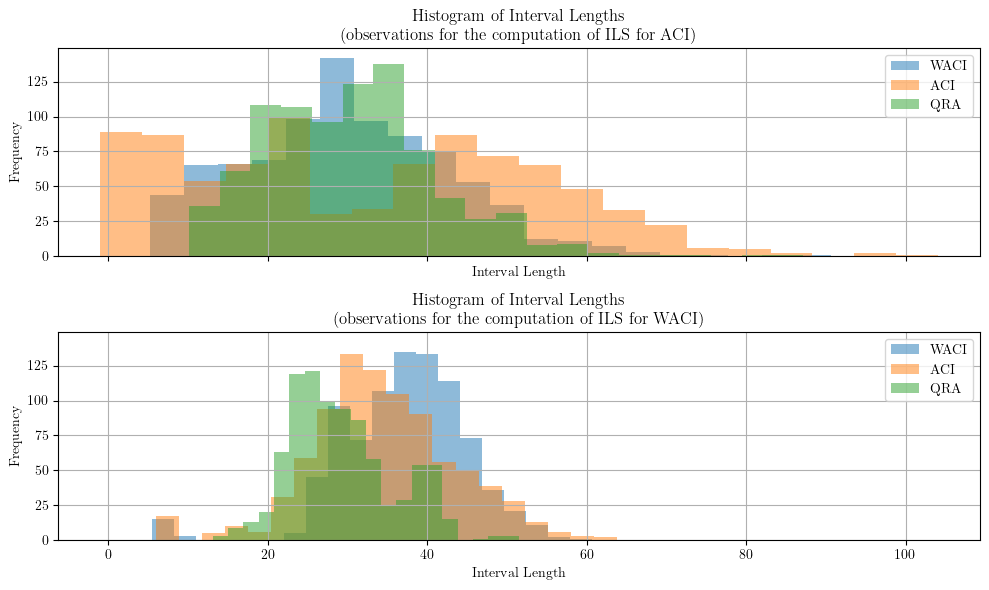

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(10,6), sharex=True, sharey=True)
df[df['apply_ils_aci_qra'] == 1]['length_waci_qra'].hist(bins=20, alpha=0.5, label='WACI', ax=ax[0])
df[df['apply_ils_aci_qra'] == 1]['length_aci_qra'].hist(bins=20, alpha=0.5, label='ACI', ax=ax[0])
df[df['apply_ils_aci_qra'] == 1]['length_qra'].hist(bins=20, alpha=0.5, label='QRA', ax=ax[0])
ax[0].set_xlabel('Interval Length')
ax[0].set_ylabel('Frequency')
ax[0].set_title('Histogram of Interval Lengths\n(observations for the computation of ILS for ACI)')
ax[0].legend()

df[df['apply_ils_waci_qra'] == 1]['length_waci_qra'].hist(bins=20, alpha=0.5, label='WACI', ax=ax[1])
df[df['apply_ils_waci_qra'] == 1]['length_aci_qra'].hist(bins=20, alpha=0.5, label='ACI', ax=ax[1])
df[df['apply_ils_waci_qra'] == 1]['length_qra'].hist(bins=20, alpha=0.5, label='QRA', ax=ax[1])
ax[1].set_xlabel('Interval Length')
ax[1].set_ylabel('Frequency')
ax[1].set_title('Histogram of Interval Lengths\n(observations for the computation of ILS for WACI)')
ax[1].legend()

plt.tight_layout()
plt.savefig("Images/explanation_ils.pdf", bbox_inches='tight', dpi=300)

In [11]:
df['qra_covers'] = ((df['preds_inf_qra'] <= df['real']) & (df['real'] <= df['preds_sup_qra']))
df['waci_qra_covers'] = ((df['preds_inf_waci_qra'] <= df['real']) & (df['real'] <= df['preds_sup_waci_qra']))
df['aci_qra_covers'] = ((df['preds_inf_aci_qra'] <= df['real']) & (df['real'] <= df['preds_sup_aci_qra']))

df['color_scatter_plot_aci'] = np.nan
df['color_scatter_plot_waci'] = np.nan

df.loc[(df['qra_covers']) & (df['aci_qra_covers']), 'color_scatter_plot_aci'] = 'black'
df.loc[(df['qra_covers']) & (~df['aci_qra_covers']), 'color_scatter_plot_aci'] = 'C1'
df.loc[(~df['qra_covers']) & (df['aci_qra_covers']), 'color_scatter_plot_aci'] = 'C2'
df.loc[(~df['qra_covers']) & (~df['aci_qra_covers']), 'color_scatter_plot_aci'] = 'black'

df.loc[(df['qra_covers']) & (df['waci_qra_covers']), 'color_scatter_plot_waci'] = 'black'
df.loc[(df['qra_covers']) & (~df['waci_qra_covers']), 'color_scatter_plot_waci'] = 'C1'
df.loc[(~df['qra_covers']) & (df['waci_qra_covers']), 'color_scatter_plot_waci'] = 'C2'
df.loc[(~df['qra_covers']) & (~df['waci_qra_covers']), 'color_scatter_plot_waci'] = 'black'

C:\Users\Usuario\AppData\Local\Temp\ipykernel_3672\1638666583.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'black' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[(df['qra_covers']) & (df['aci_qra_covers']), 'color_scatter_plot_aci'] = 'black'
C:\Users\Usuario\AppData\Local\Temp\ipykernel_3672\1638666583.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'black' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[(df['qra_covers']) & (df['waci_qra_covers']), 'color_scatter_plot_waci'] = 'black'


In [12]:
df_apply_ils_aci_qra = df[df['apply_ils_aci_qra'] == 1]
df_apply_ils_waci_qra = df[df['apply_ils_waci_qra'] == 1]

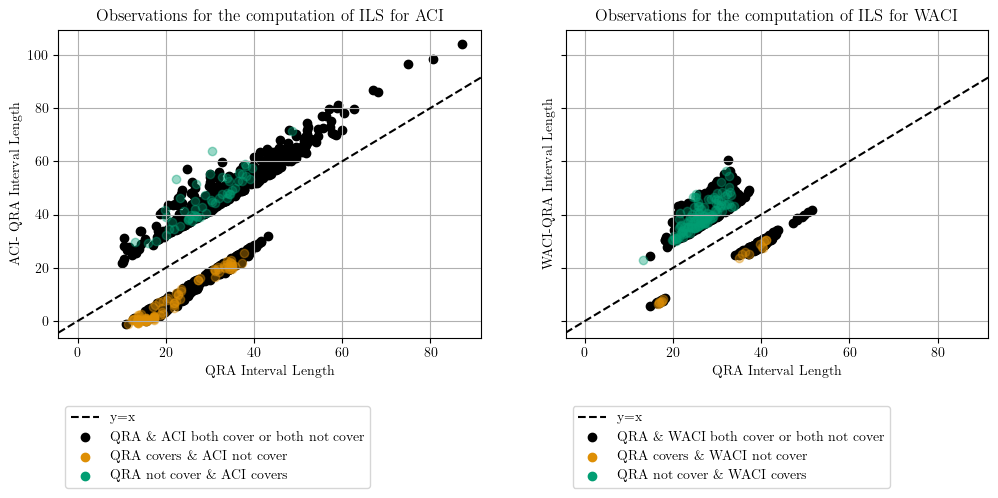

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
# ax[0].scatter(df_apply_ils_aci_qra.length_qra, df_apply_ils_aci_qra.length_aci_qra, color=df_apply_ils_aci_qra.color_scatter_plot_aci, alpha=0.4)
ax[0].scatter(df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'black'].length_qra, df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'black'].length_aci_qra, color='black', alpha=1)
ax[0].scatter(df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'C1'].length_qra, df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'C1'].length_aci_qra, color=colors[1], alpha=0.4)
ax[0].scatter(df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'C2'].length_qra, df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci == 'C2'].length_aci_qra, color=colors[2], alpha=0.4)
ax[0].set_xlabel('QRA Interval Length')
ax[0].set_ylabel('ACI- QRA Interval Length')
ax[0].axline((0, 0), slope=1, color='black', linestyle='--', label='y=x')
ax[0].scatter([], [], color='black', label='QRA \\& ACI both cover or both not cover')
ax[0].scatter([], [], color=colors[1], label='QRA covers \\& ACI not cover')
ax[0].scatter([], [], color=colors[2], label='QRA not cover \\& ACI covers')
ax[0].legend(bbox_to_anchor=(0, -0.2), loc='upper left')
ax[0].grid()
ax[0].set_title('Observations for the computation of ILS for ACI')

ax[1].scatter(df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'black'].length_qra, df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'black'].length_waci_qra, color='black', alpha=1)
ax[1].scatter(df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'C1'].length_qra, df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'C1'].length_waci_qra, color=colors[1], alpha=0.4)
ax[1].scatter(df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'C2'].length_qra, df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci == 'C2'].length_waci_qra, color=colors[2], alpha=0.4)
ax[1].set_xlabel('QRA Interval Length')
ax[1].set_ylabel('WACI-QRA Interval Length')
ax[1].axline((0, 0), slope=1, color='black', linestyle='--', label='y=x')
ax[1].scatter([], [], color='black', label='QRA \\& WACI both cover or both not cover')
ax[1].scatter([], [], color=colors[1], label='QRA covers \\& WACI not cover')
ax[1].scatter([], [], color=colors[2], label='QRA not cover \\& WACI covers')
ax[1].legend(bbox_to_anchor=(0, -0.2), loc='upper left')
ax[1].grid()
ax[1].set_title('Observations for the computation of ILS for WACI')
plt.savefig("Images/explanation_ils_scatter.pdf", bbox_inches='tight', dpi=300)

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
ax[0].scatter(df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci != 'C0'].length_qra, df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci != 'C0'].length_aci_qra, color=df_apply_ils_aci_qra[df_apply_ils_aci_qra.color_scatter_plot_aci != 'C0'].color_scatter_plot_aci, alpha=0.5)
ax[0].set_xlabel('QRA Interval Length')
ax[0].set_ylabel('ACI- QRA Interval Length')
ax[0].axline((0, 0), slope=1, color='black', linestyle='--', label='y=x')
# ax[0].scatter([], [], color='C0', label='QRA covers & ACI covers')
ax[0].scatter([], [], color='C1', label='QRA covers & ACI not cover')
ax[0].scatter([], [], color='C2', label='QRA not cover & ACI covers')
ax[0].scatter([], [], color='C3', label='QRA not cover & ACI not cover')
ax[0].legend(bbox_to_anchor=(0, -0.2), loc='upper left')
ax[0].grid()

ax[1].scatter(df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci != 'C0'].length_qra, df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci != 'C0'].length_waci_qra, color=df_apply_ils_waci_qra[df_apply_ils_waci_qra.color_scatter_plot_waci != 'C0'].color_scatter_plot_waci, alpha=0.5)
ax[1].set_xlabel('QRA Interval Length')
ax[1].set_ylabel('WACI-QRA Interval Length')
ax[1].axline((0, 0), slope=1, color='black', linestyle='--', label='y=x')
# ax[1].scatter([], [], color='C0', label='QRA covers & WACI covers')
ax[1].scatter([], [], color='C1', label='QRA covers & WACI not cover')
ax[1].scatter([], [], color='C2', label='QRA not cover & WACI covers')
ax[1].scatter([], [], color='C3', label='QRA not cover & WACI not cover')
ax[1].legend(bbox_to_anchor=(0, -0.2), loc='upper left')
ax[1].grid()

Error in callback <function _draw_all_if_interactive at 0x000002023D7AA980> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: latex was not able to process the following string:
b'QRA covers & ACI not cover'

Here is the full command invocation and its output:

latex -interaction=nonstopmode --halt-on-error file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.24 (MiKTeX 22.3) (preloaded format=latex.fmt)
 restricted \write18 enabled.
entering extended mode
(file.tex
LaTeX2e <2022-06-01> pre-release-0 (develop 2022-12-26 branch)
L3 programming layer <2022-06-02>
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\article.cls
Document Class: article 2021/10/04 v1.4n Standard LaTeX document class
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\size10.clo))
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/type1cm\type1cm.sty)
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/cm-super\type1ec.sty
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\t1cmr.fd))
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\inputenc.sty)

RuntimeError: latex was not able to process the following string:
b'QRA covers & ACI not cover'

Here is the full command invocation and its output:

latex -interaction=nonstopmode --halt-on-error file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.24 (MiKTeX 22.3) (preloaded format=latex.fmt)
 restricted \write18 enabled.
entering extended mode
(file.tex
LaTeX2e <2022-06-01> pre-release-0 (develop 2022-12-26 branch)
L3 programming layer <2022-06-02>
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\article.cls
Document Class: article 2021/10/04 v1.4n Standard LaTeX document class
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\size10.clo))
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/type1cm\type1cm.sty)
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/cm-super\type1ec.sty
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\t1cmr.fd))
(C:\Users\Usuario\AppData\Local\Programs\MiKTeX\tex/latex/base\inputenc.sty)

<Figure size 1200x400 with 2 Axes>

In [35]:
from metrics import winkler_score, empirical_coverage

In [39]:
print('Obs ILS ACI - ACI:', winkler_score(df_apply_ils_aci_qra['real'], df_apply_ils_aci_qra['preds_sup_aci_qra'], df_apply_ils_aci_qra['preds_inf_aci_qra'], alpha=0.2))
print('Obs ILS ACI - WACI:', winkler_score(df_apply_ils_aci_qra['real'], df_apply_ils_aci_qra['preds_sup_waci_qra'], df_apply_ils_aci_qra['preds_inf_waci_qra'], alpha=0.2))
print()
print('Obs ILS WACI - ACI:', winkler_score(df_apply_ils_waci_qra['real'], df_apply_ils_waci_qra['preds_sup_aci_qra'], df_apply_ils_waci_qra['preds_inf_aci_qra'], alpha=0.2))
print('Obs ILS WACI - WACI:', winkler_score(df_apply_ils_waci_qra['real'], df_apply_ils_waci_qra['preds_sup_waci_qra'], df_apply_ils_waci_qra['preds_inf_waci_qra'], alpha=0.2))

Obs ILS ACI - ACI: 44.19783712532316
Obs ILS ACI - WACI: 45.20094456663861

Obs ILS WACI - ACI: 51.587198049003284
Obs ILS WACI - WACI: 50.099626830622576


In [20]:
empirical_coverage(df_apply_ils_aci_qra['real'], df_apply_ils_aci_qra['preds_sup_aci_qra'], df_apply_ils_aci_qra['preds_inf_aci_qra']), empirical_coverage(df_apply_ils_waci_qra['real'], df_apply_ils_waci_qra['preds_sup_waci_qra'], df_apply_ils_waci_qra['preds_inf_waci_qra'])

(np.float64(79.28653624856156), np.float64(84.69505178365938))

# Tema MCD

In [28]:
df_mcd = pd.read_csv("Results/df_mean_deviation_coverage_by_interval_length_alpha_0.2.csv", index_col=0)

In [29]:
df_mcd

,hqr,hqr_w,qra,aci_hqr,aci_hqr_w,aci_qra,waci_hqr,waci_hqr_w,waci_qra,dcp_hqr,dcp_hqr_w,dcp_qra
0,6.238588,6.115611,8.337017,5.054505,4.890965,8.011144,4.995888,4.830477,6.624259,8.309735,9.301984,10.913079
1,5.877737,6.545491,8.892172,4.562876,5.297534,7.264500,4.347566,4.858075,6.691369,6.847734,7.324204,10.620213
2,7.018973,8.144208,11.542134,6.520866,7.738828,9.563090,5.898817,6.601080,7.218004,6.170724,4.935358,7.715985
3,3.408995,3.602339,6.502281,3.468967,3.324565,5.483570,3.239990,3.667142,5.690630,5.704081,7.256089,8.914318
4,5.353235,5.723390,6.278654,6.701146,6.863043,6.642280,4.495140,4.619847,4.703475,9.310659,10.260939,13.132723
...,...,...,...,...,...,...,...,...,...,...,...,...
995,7.298085,7.447580,6.080892,7.239634,8.467940,7.387359,5.776482,5.738835,4.577510,6.284850,6.628659,9.026634
996,4.258055,4.397136,5.504277,5.173773,5.627788,5.440590,3.927176,3.416922,4.039504,7.089314,7.962558,10.219279
997,7.376336,8.315733,10.896379,7.316275,8.134996,9.145266,6.732712,7.100952,9.523545,6.132033,6.849579,10.745341
998,5.817706,5.997853,5.622485,3.952932,5.606575,5.847988,3.658164,4.879376,4.832079,9.146340,9.283902,9.405703


In [30]:
df

,full_date,date,hour,real,pred1,pred2,pred3,mean_pred,std_pred,preds_inf_hqr,...,preds_sup_dcp_hqr,apply_ils_waci_qra,apply_ils_aci_qra,length_waci_qra,length_aci_qra,qra_covers,waci_qra_covers,aci_qra_covers,color_scatter_plot_aci,color_scatter_plot_waci
0,2024-01-01 01:00:00,2024-01-01,1.0,63.33,82.898308,62.355480,50.768466,65.340751,13.285721,35.319085,...,88.530945,0,0,38.823779,38.823779,True,True,True,black,black
1,2024-01-01 02:00:00,2024-01-01,2.0,50.09,75.484566,55.283073,49.170277,59.979305,11.244299,32.401403,...,81.841764,0,0,36.941035,36.941035,True,True,True,black,black
2,2024-01-01 03:00:00,2024-01-01,3.0,47.50,70.086792,50.086437,46.769143,55.647457,10.299576,29.068646,...,76.991897,0,0,39.209011,39.209011,True,True,True,black,black
3,2024-01-01 04:00:00,2024-01-01,4.0,43.50,64.816544,46.034496,42.204944,51.018661,9.881043,24.689453,...,72.274791,0,0,39.178262,39.178262,True,True,True,black,black
4,2024-01-01 05:00:00,2024-01-01,5.0,42.50,59.261833,43.651333,38.575189,47.162785,8.802728,22.051485,...,67.770927,0,0,41.900989,41.900989,True,True,True,black,black
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8683,2024-12-27 20:00:00,2024-12-27,20.0,159.02,152.683075,150.121002,161.206871,154.670316,4.738915,142.828034,...,179.468803,0,0,26.088933,25.238294,True,True,True,black,black
8684,2024-12-27 21:00:00,2024-12-27,21.0,161.50,152.683075,149.482620,160.704530,154.290075,4.720145,142.444705,...,179.015550,0,0,28.647233,24.796826,True,True,True,black,black
8685,2024-12-27 22:00:00,2024-12-27,22.0,158.50,148.447403,146.330612,154.686853,149.821623,3.547116,138.777311,...,172.079024,0,0,30.262742,32.133747,True,True,True,black,black
8686,2024-12-27 23:00:00,2024-12-27,23.0,147.63,135.195251,139.106827,142.328271,138.876783,2.916583,127.822938,...,158.879992,0,0,30.394176,27.995313,True,True,True,black,black


In [34]:
def mean_deviation_coverage_by_interval_length(df, model, quantile_step, alpha):
    df['length_' + model] = df[f'preds_sup_{model}'] - df[f'preds_inf_{model}']
    dict_lengths = {model: [np.quantile(df[f'length_{model}'], i) for i in np.arange(0, 1.01, quantile_step)]}
    dict_coverages = {model: []}
    for i_quantile in range(len(dict_lengths[model])-1):
        length_min_model, length_max_model = dict_lengths[model][i_quantile], dict_lengths[model][i_quantile+1]
        df_aux_model = df[(df[f'length_{model}'] >= length_min_model) & (df[f'length_{model}'] <= length_max_model)]
        dict_coverages[model].append(empirical_coverage(df_aux_model['real'], df_aux_model[f'preds_sup_{model}'], df_aux_model[f'preds_inf_{model}']))
    return np.mean(np.abs(np.array(dict_coverages[model]) - (1-alpha)*100))

In [35]:
vals_computed = []
for col in df_mcd.columns:
    mcd_col = mean_deviation_coverage_by_interval_length(df, col, 0.05, 0.2)
    vals_computed.append(mcd_col)

NameError: name 'empirical_coverage' is not defined

In [49]:
df_mcd.columns

Index(['hqr', 'hqr_w', 'qra', 'aci_hqr', 'aci_hqr_w', 'aci_qra', 'waci_hqr',
       'waci_hqr_w', 'waci_qra', 'dcp_hqr', 'dcp_hqr_w', 'dcp_qra'],
      dtype='object')

In [47]:
vals_computed

[np.float64(4.825785264050003),
 np.float64(5.550611790878753),
 np.float64(7.427061814714764),
 np.float64(4.858414110916892),
 np.float64(5.686635944700461),
 np.float64(6.911409502621962),
 np.float64(3.839186397584617),
 np.float64(4.419381323163302),
 np.float64(5.37507283224747),
 np.float64(6.590054784502863),
 np.float64(7.469622331691298),
 np.float64(10.013401133534616)]

C:\Users\Usuario\AppData\Local\Temp\ipykernel_21532\3425531861.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_mcd[col], hist=True, kde=True, ax=ax)


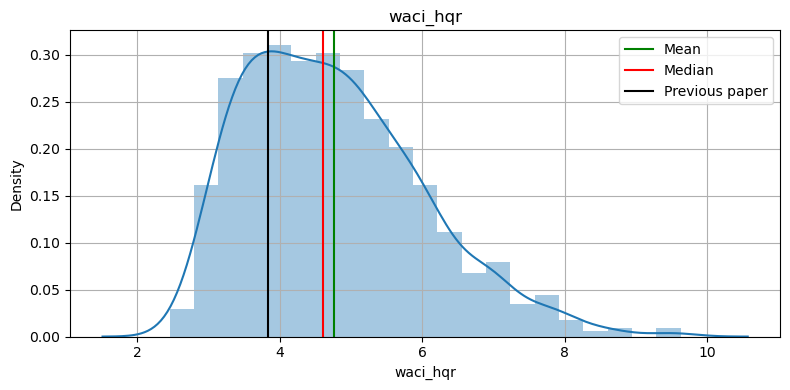

In [36]:
vals_previous_paper = [4.83, 5.55, 7.43, 4.86, 5.69, 6.91, 3.84, 4.42, 5.38, np.nan, np.nan, np.nan]
for idx, col in enumerate(df_mcd.columns):
    if col == 'waci_hqr':
        fig, ax = plt.subplots(1, 1, figsize=(8, 4))
        sns.distplot(df_mcd[col], hist=True, kde=True, ax=ax)
        ax.axvline(df_mcd[col].mean(), label='Mean', color='green')
        ax.axvline(df_mcd[col].median(), label='Median', color='red')
        ax.axvline(vals_previous_paper[idx], label='Previous paper', color='black')
        # ax.axvline(vals_computed[idx], label='Computed', color='blue')
        ax.grid()
        ax.set_title(col)
        ax.legend()
        plt.tight_layout()
        plt.savefig(f"Images/{col}_distribution_mcd.pdf", bbox_inches='tight', dpi=300)